# Energy Power Grid Bangladesh

# Práctica: Regresión Lineal

- Asignatura: Machine Learning
- Nombre: Andrea Georgina Rodríguez Pacheco
- Matrícula: 395699
- Dataset: PGCB Hourly Generation Dataset (Bangladesh)

In [97]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

# 1. Carga del conjunto de datos

Utilice el conjunto PGCB Hourly Generation Dataset (Bangladesh), disponible en el UCI Machine Learning Repository.

El conjunto contiene información horaria de generación, demanda, fuentes de energía e importaciones de la red eléctrica de Bangladesh (Power Grid Company of Bangladesh).

In [99]:
import zipfile

zip_path = "../pgcb+hourly+generation+dataset+(bangladesh).zip"

with zipfile.ZipFile(zip_path) as z:
    X = pd.read_excel(z.open("PGCB_date_power_demand.xlsx"))

TARGET = "load_shedding"

# print(X.head(5))
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92650 entries, 0 to 92649
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              92650 non-null  datetime64[ns]
 1   generation_mw         92650 non-null  float64       
 2   demand_mw             92650 non-null  int64         
 3   load_shedding         92650 non-null  int64         
 4   gas                   92650 non-null  int64         
 5   liquid_fuel           92650 non-null  int64         
 6   coal                  92650 non-null  int64         
 7   hydro                 92650 non-null  int64         
 8   solar                 70517 non-null  float64       
 9   wind                  18676 non-null  float64       
 10  india_bheramara_hvdc  92650 non-null  int64         
 11  india_tripura         92650 non-null  int64         
 12  india_adani           7338 non-null   float64       
 13  nepal           

### Preguntas
**¿Cuál es el objetivo general del problema?**

Predecir los puntos críticos donde la demanda excede a la capacidad de suministro y puede producirse un desprendimiento de carga.

**¿Qué representa cada instancia del dataset?**
Las métricas obteneidas por hora 

**¿Cuál es la variable que se desea predecir?**
Load_shedding

**¿Por qué este problema corresponde a aprendizaje supervisado?**

Buscamos predecir el volumen de desprendimiento de energía en un determinado momento, a partir de datos donde ese dato ya es conocido.

**¿Por qué corresponde específicamente a un problema de regresión**
Porque buscamos un valor continuo no una categoría.

## 2. Inspección inicial del dataset
Antes de dividir los datos o realizar el análisis exploratorio, realizaremos una inspección estructural inicial.

En esta etapa deberá identificar:

* dimensiones del dataset
* nombres de las columnas
* tipos de datos
* primeras observaciones
* valores faltantes
* registros duplicados
* posibles problemas de formato o codificación.

In [100]:
# Estructura genérica del dataset
length = len("Dimensiones del dataset")
border = "*" * (length + 4)

print(border)
print(f"* Dimensiones de mi dataset *")
print("Filas:", X.shape[0])
print("Columnas:", X.shape[1])
print(border)
print(f"* Columnas *")
print(X.columns.to_list())
print(border)
print(f"* Tipos de datos *")
print(X.dtypes)
print(border)

***************************
* Dimensiones de mi dataset *
Filas: 92650
Columnas: 15
***************************
* Columnas *
['datetime', 'generation_mw', 'demand_mw', 'load_shedding', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal', 'remarks']
***************************
* Tipos de datos *
datetime                datetime64[ns]
generation_mw                  float64
demand_mw                        int64
load_shedding                    int64
gas                              int64
liquid_fuel                      int64
coal                             int64
hydro                            int64
solar                          float64
wind                           float64
india_bheramara_hvdc             int64
india_tripura                    int64
india_adani                    float64
nepal                          float64
remarks                         object
dtype: object
***************************


In [101]:
print(f"* Valores faltantes *")
print(X.isnull().sum())
print(border)
print(f"* Valores duplicados *")
print(X.duplicated().sum())
print(border)
print(f"* Rango *")
print(X[TARGET].max())
print(X[TARGET].min())
print(border)
print(f"* Vista previa del dataset *")
print(X.head().to_string(index=False))
print(border)

print(f"* Resumen estadístico (variables numéricas) *")
print(X.describe().round(2).to_string())
print(border)

* Valores faltantes *
datetime                    0
generation_mw               0
demand_mw                   0
load_shedding               0
gas                         0
liquid_fuel                 0
coal                        0
hydro                       0
solar                       0
wind                     8664
india_bheramara_hvdc        0
india_tripura               0
india_adani             19959
nepal                   21944
remarks                 25163
dtype: int64
***************************
* Valores duplicados *
0
***************************
* Rango *
4847
0
***************************
* Vista previa del dataset *
           datetime  generation_mw  demand_mw  load_shedding  gas  liquid_fuel  coal  hydro  solar  wind  india_bheramara_hvdc  india_tripura  india_adani  nepal remarks
2022-06-17 13:00:00         8384.0       8384              0 4554         2164   525     66   64.0   NaN                   935             92          NaN    NaN     NaN
2022-06-17 14:00:00 

### Preguntas
**¿Cuántas instancias contiene el dataset?**

92659

**¿Cuántas columnas contiene?**
15

**¿Cuáles son los nombres de las variables?**

datetime, generation_mw, demand_mw, load_shedding, gas, liquid_fuel, coal, hydro, solar, wind, india_bheramara_hvdc,india_tripura, india_adani, nepal, remarks   

**¿Qué variables son numéricas?**
generation_mw
demand_mw
load_shedding
gas
liquid_fuel
coal
hydro
solar
wind
india_bheramara_hvdc
india_tripura
india_adani
nepal

**¿Qué variables son categóricas?**
remarks

**¿Existen valores faltantes? ¿En qué variables?**

wind                     8664
india_adani             19959
nepal                   21944
remarks                 25163

**¿Existen registros duplicados? ¿Cuántos?**
si, 160

**¿Cuál es el tipo de dato de datetime?**
datetime

**¿Es conveniente utilizar datetime directamente como entrada del modelo?**

No, habría que aplicarle alguna transformación de tipo binaria como one hot encoding o bien codificación cíclica de las horas.


**¿Detecta algún problema evidente de formato, codificación o tipo de dato?**

Remarks, es una variable categórica con muy poca varianza

**¿La variable objetivo se encuentra en un rango razonable para representar el load shedding en MW?**
si, 4847


## 3. Separación de X e y
Separe las características y la variable objetivo.

X=variables predictoras
y=load_shedding

### Periodo de estudio
Se utilizan únicamente los **últimos tres años** del registro (desde junio de 2022). Entre 2015 y 2021 el load shedding era prácticamente inexistente (menos del 0.5% de las horas), mientras que desde 2022 ocurre en más de la mitad de las horas. Al combinar ambos periodos, el modelo aprende sobre todo el régimen antiguo (load shedding ≈ 0) y no generaliza al actual. Limitar el estudio al periodo reciente permite que Train y Test representen las mismas condiciones de operación de la red. Se eligen tres años (y no dos) para que Train contenga al menos dos ciclos anuales completos: el load shedding es estacional (alto en verano, casi nulo en invierno) y con solo dos años el conjunto Test quedaría concentrado en una sola temporada.

In [ ]:
# Eliminación de registros duplicados: un mismo registro en Train y en Test sería fuga de información
X = X.drop_duplicates().reset_index(drop=True)

# Orden cronológico (el archivo viene en orden descendente) y una sola fila por marca de tiempo
X = X.sort_values("datetime").drop_duplicates(subset="datetime", keep="last").reset_index(drop=True)

# Eliminación de valores físicamente imposibles (errores de captura, p. ej. generation_mw = 64,526,500).
# Los límites son fijos, basados en la capacidad de la red de Bangladesh (pico histórico < 17,000 MW),
# no se calculan a partir de los datos, por lo que pueden aplicarse antes de la partición sin fuga de información.
max_mw = {
    "generation_mw": 20000, "demand_mw": 20000, "load_shedding": 5000,
    "gas": 15000, "liquid_fuel": 10000, "coal": 10000, "hydro": 1000,
    "india_bheramara_hvdc": 2000, "india_tripura": 500, "india_adani": 3000,
}
invalid = np.zeros(len(X), dtype=bool)
for col, limit in max_mw.items():
    invalid |= X[col] > limit
print("Registros con valores imposibles eliminados:", invalid.sum())
X = X[~invalid].reset_index(drop=True)

# Periodo de estudio: últimos tres años del registro (desde mediados de 2022).
# A partir de 2022 el load shedding pasó de ser casi inexistente a ocurrir en más de la mitad de las horas;
# se analiza solo el régimen actual, con suficientes temporadas completas para que Train cubra el ciclo anual.
study_years = 3
end_date = X["datetime"].max()
start_date = end_date - pd.DateOffset(years=study_years)
X = X[X["datetime"] > start_date].reset_index(drop=True)
print("Periodo de estudio:", X["datetime"].min(), "→", X["datetime"].max(), "| registros:", len(X))

X_var = X.drop(TARGET, axis=1)
y_var = X[TARGET].copy()

Registros con valores imposibles eliminados: 168
Periodo de estudio: 2022-06-17 13:00:00 → 2025-06-17 12:00:00 | registros: 27285


### Preguntas

**¿Cuántas características contiene inicialmente X?**

**¿Qué dimensión tiene X?**

**¿Qué dimensión tiene y?**

**¿Qué representa cada fila de X?**

**¿Qué representa cada columna de X?**

**¿Verificó que la variable objetivo no se encuentre incluida dentro de X?**

**¿Existe alguna característica que requiera tratamiento especial posteriormente?**

# 4. Partición Train/Test temporal
Realice una partición **cronológica**:

80% más antiguo → Train

20% más reciente → Test

A partir de este momento, el conjunto Test deberá permanecer aislado hasta la evaluación final.

### Restricción de eventos futuros
Los registros forman una serie de tiempo: observaciones consecutivas están fuertemente autocorrelacionadas. Con una partición aleatoria (aunque sea estratificada):

- El modelo se entrenaría con registros **posteriores** a los de Test, es decir, usaría información del futuro para "predecir" el pasado.
- Cada registro de Test tendría casi siempre un vecino inmediato (la hora anterior o siguiente) en Train, por lo que el error de Test resultaría artificialmente bajo.

Por ello la partición se realiza con `shuffle=False` sobre los datos ordenados por `datetime`: todo Train es anterior a todo Test, igual que ocurriría al usar el modelo en producción.

### Balance de load shedding (solo diagnóstico)
La variable objetivo está muy desbalanceada (la mayoría de los registros tienen `load_shedding = 0`). Una estratificación obligaría a mezclar periodos, por lo que **no se aplica**; en su lugar se reporta la proporción de cada rango fijo de `load_shedding` (MW: 0, 1–100, 100–300, 300–750, >750) en Train y en Test para identificar diferencias de distribución entre ambos periodos.

In [127]:
train_set_x, test_set_x, train_set_y, test_set_y = train_test_split(
    X_var, y_var, test_size=0.2, shuffle=False
)
print(f"* Dimensiones de conjunto de entrenamiento X*")
print("Filas:", train_set_x.shape[0])
print("Columnas:", train_set_x.shape[1])
print(f"* Dimensiones de conjunto de prueba X*")
print("Filas:", test_set_x.shape[0])
print("Columnas:", test_set_x.shape[1])

print(f"* Dimensiones de conjunto de entrenamiento y *")
print("Filas:", train_set_y.shape[0])
print(f"* Dimensiones de conjunto de prueba y*")
print("Filas:", test_set_y.shape[0])

# Restricción de eventos futuros: todo Train debe ser anterior a todo Test
print(f"* Periodo de cada conjunto *")
print("Train:", train_set_x["datetime"].min(), "→", train_set_x["datetime"].max())
print("Test: ", test_set_x["datetime"].min(), "→", test_set_x["datetime"].max())
assert train_set_x["datetime"].max() < test_set_x["datetime"].min()

# Diagnóstico: proporción de cada rango de load shedding en Train y Test
ls_bins = [-np.inf, 0, 100, 300, 750, np.inf]
ls_labels = ["0", "1-100", "100-300", "300-750", ">750"]
strata = pd.cut(y_var, bins=ls_bins, labels=ls_labels)

print(f"* Proporción por rango de load shedding (Train vs Test) *")
print(pd.DataFrame({
    "Train": strata.loc[train_set_x.index].value_counts(normalize=True),
    "Test": strata.loc[test_set_x.index].value_counts(normalize=True)
}).sort_index().round(4))


* Dimensiones de conjunto de entrenamiento X*
Filas: 21828
Columnas: 14
* Dimensiones de conjunto de prueba X*
Filas: 5457
Columnas: 14
* Dimensiones de conjunto de entrenamiento y *
Filas: 21828
* Dimensiones de conjunto de prueba y*
Filas: 5457
* Periodo de cada conjunto *
Train: 2022-06-17 13:00:00 → 2024-11-10 18:00:00
Test:  2024-11-10 18:30:00 → 2025-06-17 12:00:00
* Proporción por rango de load shedding (Train vs Test) *
                Train    Test
load_shedding                
0              0.4157  0.6575
1-100          0.1159  0.2465
100-300        0.1518  0.0825
300-750        0.1536  0.0125
>750           0.1630  0.0011


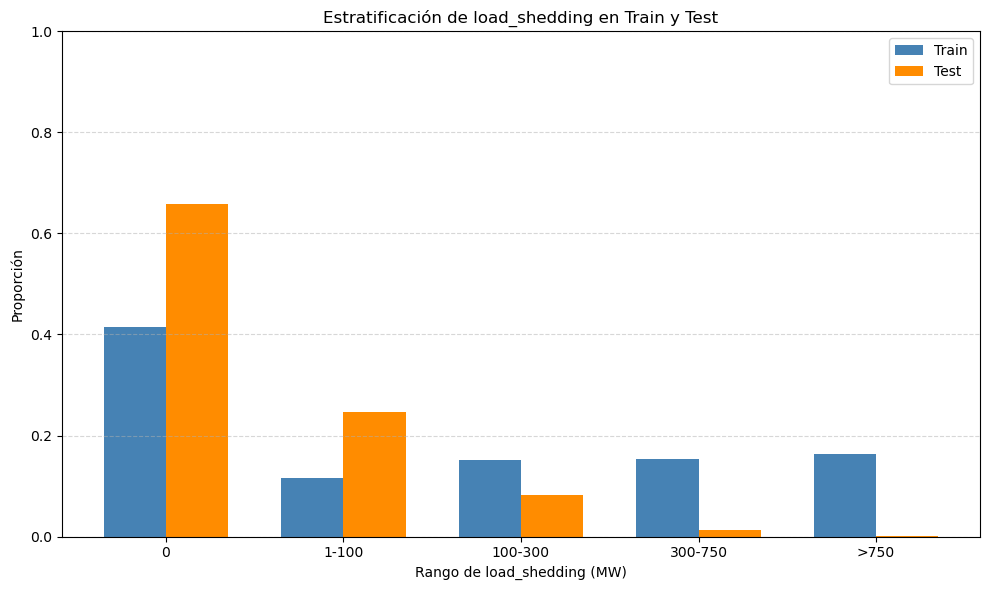

In [131]:
# Plot de la estratificación de la variable objetivo en Train y Test
train_strata = pd.cut(train_set_y, bins=ls_bins, labels=ls_labels, right=True)
test_strata = pd.cut(test_set_y, bins=ls_bins, labels=ls_labels, right=True)

train_prop = train_strata.value_counts(normalize=True).reindex(ls_labels, fill_value=0)
test_prop = test_strata.value_counts(normalize=True).reindex(ls_labels, fill_value=0)

x = np.arange(len(ls_labels))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, train_prop.values, width=width, label="Train", color="steelblue")
plt.bar(x + width/2, test_prop.values, width=width, label="Test", color="darkorange")

plt.xticks(x, ls_labels)
plt.xlabel("Rango de load_shedding (MW)")
plt.ylabel("Proporción")
plt.ylim(0, 1)
plt.title("Estratificación de load_shedding en Train y Test")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Periodo de estudio: demanda, producción y load shedding
Vista general de las series originales en el periodo de estudio, indicando la división entre Train y Test. Se grafican promedios diarios. Esta gráfica es descriptiva: las decisiones de modelado del EDA se toman únicamente con Train.

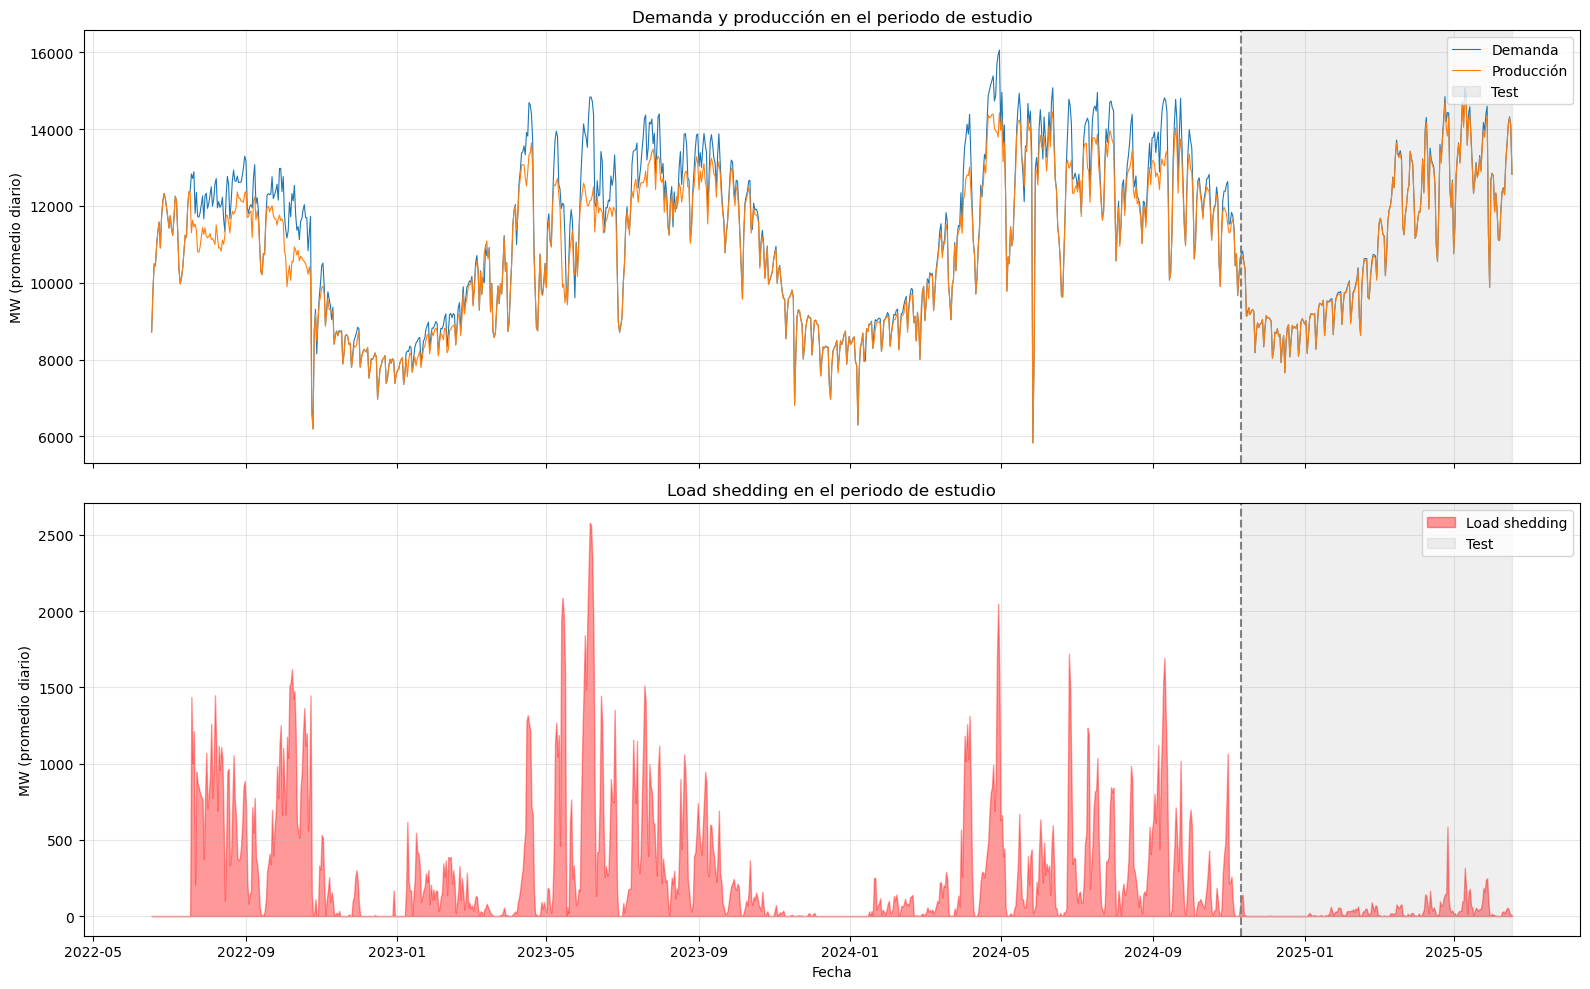

In [ ]:
# Series originales en el periodo de estudio (promedios diarios)
timeline = X[["datetime", "demand_mw", "generation_mw", TARGET]]
daily = timeline.groupby(timeline["datetime"].dt.date).mean(numeric_only=True)
daily.index = pd.to_datetime(daily.index)
split_date = test_set_x["datetime"].min()

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

axes[0].plot(daily.index, daily["demand_mw"], linewidth=0.8, label="Demanda")
axes[0].plot(daily.index, daily["generation_mw"], linewidth=0.8, label="Producción")
axes[0].set_ylabel("MW (promedio diario)")
axes[0].set_title("Demanda y producción en el periodo de estudio")

axes[1].fill_between(daily.index, daily[TARGET], color="red", alpha=0.4, label="Load shedding")
axes[1].set_ylabel("MW (promedio diario)")
axes[1].set_xlabel("Fecha")
axes[1].set_title("Load shedding en el periodo de estudio")

for ax in axes:
    ax.axvspan(split_date, daily.index.max(), color="gray", alpha=0.12, label="Test")
    ax.axvline(split_date, color="gray", linestyle="--")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Preguntas

**¿Cuántas instancias quedaron en Train?**
21828
**¿Cuántas instancias quedaron en Test?**
5457

**¿Por qué se realiza la partición antes del EDA?**
Para evitar sacar conclusiones de comportamientos que vemos a futuro sobre todo en el caso de series temporales.

**¿Por qué el EDA detallado debe realizarse únicamente sobre Train?**
Para evitar sesgos. a partir de las tendencias identificadas a futuro, sobretodo en un problema de series temporales

**¿Qué tipo de fuga de información podría ocurrir si utilizamos Test para tomar decisiones de modelado?**
Podríamos estar "prediciendo" eventos de load shedding futuros que ya han sido aprendidos en el modelo, quizá podría tener buen rendimiento en training pero será inútil con información desconocida.

**¿Por qué Test no debe utilizarse para seleccionar hiperparámetros?**
Para evitar seleccionar hiperparámetros en el modelo y evitar data leakage.

**¿Qué representa conceptualmente el conjunto Test?**
Datos futuros que nunca han sido vistos por el modelo

## 5. Análisis Exploratorio de Datos — EDA

### 5.1 Distribución de la variable objetivo
Analice load_shedding.

### Preguntas

**¿La distribución es aproximadamente simétrica?** no, 

**¿Existe sesgo hacia valores bajos o altos?** si existe sesgo hacia valores altos

**¿Existen valores inusualmente altos o bajos?**

**¿Estos valores podrían representar errores o situaciones reales?**Si tienen una tendencia paulatina hacia valores altos, no son casos aislados atípicos

**¿En qué rango se encuentra la mayor concentración de instancias?** 13000Mw

**¿Cómo podría afectar esta distribución a las métricas de error?**

Text(0, 0.5, 'Frecuencia')

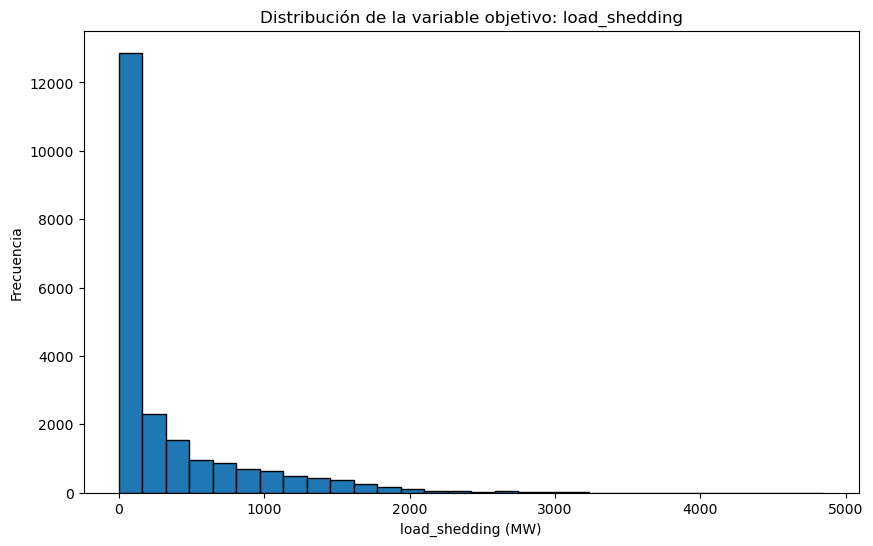

In [106]:
#Distribución de la variable objetivo
plt.figure(figsize=(10, 6))
plt.hist(train_set_y, bins=30, edgecolor='black')
plt.title('Distribución de la variable objetivo: load_shedding')
plt.xlabel('load_shedding (MW)')
plt.ylabel('Frecuencia')

### 5.2 Hora del día y load shedding
Analice la relación entre la hora del día y load_shedding.

### Preguntas

**¿La relación entre la hora y load shedding parece lineal?**

**¿A qué horas aparecen los principales picos?**
de 13:00 a20:00

**¿Los picos podrían relacionarse con horarios de mayor consumo?**
Puede ser

**¿Qué ocurre durante la madrugada?**
También hay ciertos picos

**¿Una regresión lineal utilizando la hora directamente como una variable numérica podría capturar adecuadamente este patrón?**
Quizá no por si sola pero podría ser una variable relevante

**¿Qué transformación de la hora podría ayudar a representar mejor su naturaleza periódica?**
una codificación Cíclica Coseno/Seno 


In [ ]:
# Relación entre la hora del día y load shedding
plt.figure(figsize=(10, 6))
plt.scatter(train_set_x['datetime'].dt.hour, train_set_y, alpha=0.5)
plt.title('Relación entre la hora del día y load shedding')
plt.xlabel('Hora del día')
plt.ylabel('load_shedding (MW)')

AttributeError: module 'matplotlib.pyplot' has no attribute 'lines'

<Figure size 1000x600 with 0 Axes>

### 5.3 Demanda y load shedding
Analice la relación entre demand_mw y load_shedding.

### Preguntas

**¿Existe una relación aparente entre demanda y load shedding?**

**¿La asociación observada es positiva o negativa?**

**¿Parece lineal?**

**¿Existe diferente dispersión según el rango de demanda?**

**Si observa que el load shedding aumenta conforme aumenta la demanda, ¿puede concluir que la demanda es la causa directa del aumento? Justifique.**

Text(0, 0.5, 'load_shedding (MW)')

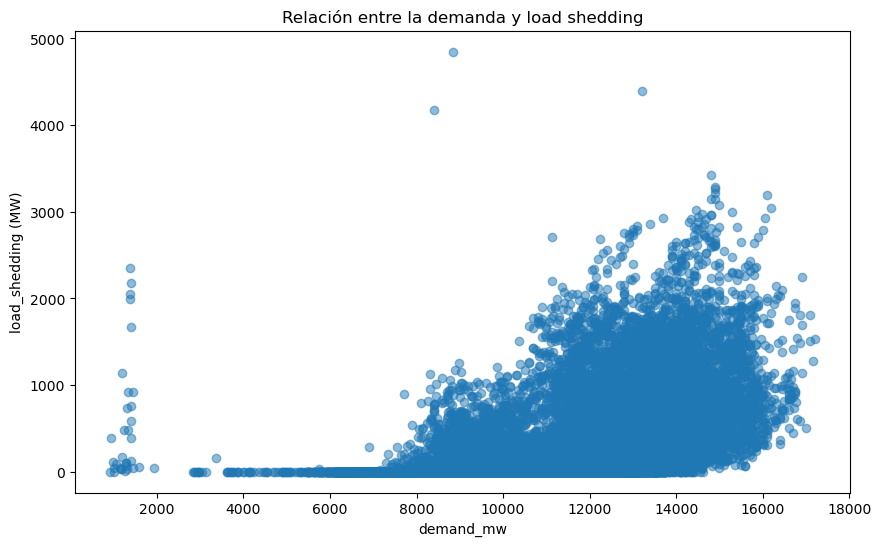

In [108]:
# Relación entre demanda y load shedding
plt.figure(figsize=(10, 6))
plt.scatter(train_set_x['demand_mw'], train_set_y, alpha=0.5)
plt.title('Relación entre la demanda y load shedding')
plt.xlabel('demand_mw')
plt.ylabel('load_shedding (MW)')

## 5.4 Otra fuente de generación
Seleccione una de las siguientes variables:

- gas
- liquid_fuel
- coal
- hydro
- solar
- india_bheramara_hvdc / india_tripura

### Preguntas

**¿Por qué seleccionó esa variable?**

**¿Qué patrón observa?**

**¿La relación parece lineal?**

**¿Existen valores inusualmente altos o bajos?**

**¿Considera que esta característica podría aportar información al modelo? Justifique.**

Text(0, 0.5, 'load_shedding (MW)')

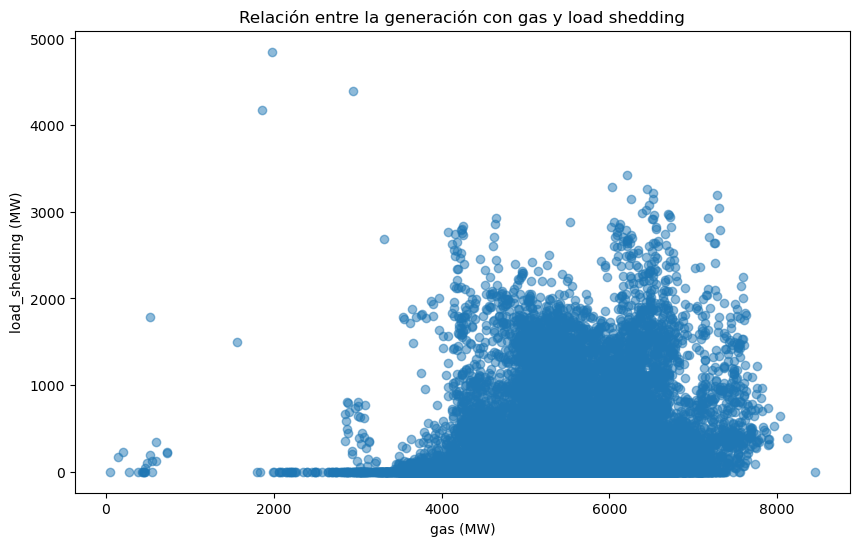

In [109]:
# Relación entre generación con gas y load shedding
plt.figure(figsize=(10, 6))
plt.scatter(train_set_x['gas'], train_set_y, alpha=0.5)
plt.title('Relación entre la generación con gas y load shedding')
plt.xlabel('gas (MW)')
plt.ylabel('load_shedding (MW)')

## 5.5 Mes del año
Analice load_shedding de acuerdo con el mes.

### Preguntas

**¿En qué mes existe mayor load shedding promedio?**

**¿En cuál existe menor?**

**¿Las diferencias parecen relevantes?**

**¿El mes debería tratarse como una variable numérica o categórica?**

Text(0, 0.5, 'load_shedding promedio (MW)')

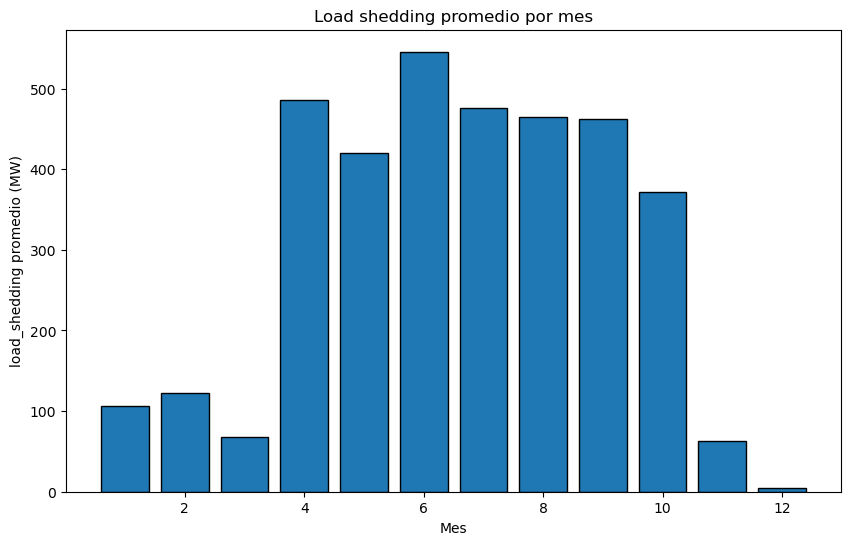

In [110]:
# Load shedding promedio por mes
monthly = train_set_y.groupby(train_set_x['datetime'].dt.month).mean()

plt.figure(figsize=(10, 6))
plt.bar(monthly.index, monthly.values, edgecolor='black')
plt.title('Load shedding promedio por mes')
plt.xlabel('Mes')
plt.ylabel('load_shedding promedio (MW)')

## 5.6 Correlaciones
Analice las correlaciones de Pearson entre las variables numéricas.

### Preguntas

**¿Qué variable presenta mayor correlación positiva con load shedding?**

**¿Cuál presenta mayor correlación negativa?**

**¿Existen variables con r ≈ 0?**

**¿Un valor r ≈ 0 significa necesariamente que una variable no es útil para predecir load shedding?**

**¿Por qué Pearson puede no detectar una relación no lineal?**

**¿Es adecuado seleccionar características únicamente con base en su correlación con la variable objetivo?**

In [111]:
numeric_variables = train_set_x.select_dtypes(include=np.number)

corr_matrix = numeric_variables.corr("pearson")

corr_with_target = pd.concat(
    [numeric_variables, train_set_y.rename(TARGET)],
    axis=1
).corr(method="pearson")[TARGET].sort_values(ascending=False)

corr_with_target

load_shedding           1.000000
demand_mw               0.542270
liquid_fuel             0.371944
generation_mw           0.367763
india_tripura           0.310693
gas                     0.241603
india_adani             0.238584
india_bheramara_hvdc    0.199620
hydro                   0.057247
solar                   0.032233
coal                    0.029335
wind                   -0.006964
nepal                        NaN
Name: load_shedding, dtype: float64

## 6. Feature Engineering
A partir de los resultados obtenidos durante el EDA, proponga y justifique al menos dos nuevas características.

Puede considerar, entre otras:

- Month
- DayOfWeek
- IsWeekend
- transformaciones cíclicas de Hour
- interacciones entre variables

### Importante
Conserve la variable datetime, o una copia del dataset original, ya que será necesaria posteriormente para realizar el experimento con partición temporal.

Las transformaciones diseñadas deberán poder aplicarse de manera reproducible tanto a Train como a nuevas observaciones.

In [134]:
# Nueva característica: Hora cíclica
def add_hour_cyclical_features(df):
    df = df.copy()
    df["Hour"] = df["datetime"].dt.hour
    hour_norm = df["Hour"] / 24.0
    df["Hour_sin"] = np.sin(2 * np.pi * hour_norm)
    df["Hour_cos"] = np.cos(2 * np.pi * hour_norm)
    return df


train_set_x = add_hour_cyclical_features(train_set_x)
test_set_x = add_hour_cyclical_features(test_set_x)

print(train_set_x[["datetime", "Hour", "Hour_sin", "Hour_cos"]].head())

             datetime  Hour  Hour_sin  Hour_cos
0 2022-06-17 13:00:00    13 -0.258819 -0.965926
1 2022-06-17 14:00:00    14 -0.500000 -0.866025
2 2022-06-17 15:00:00    15 -0.707107 -0.707107
3 2022-06-17 16:00:00    16 -0.866025 -0.500000
4 2022-06-17 17:00:00    17 -0.965926 -0.258819


In [ ]:
def add_day_of_week_features(df):
    df = df.copy()

    # Convert datetime if it is still stored as text
    if df["datetime"].dtype == object:
        df["datetime"] = pd.to_datetime(df["datetime"])

    # New feature: day of the week (Monday=0 ... Sunday=6)
    df["DayOfWeek"] = df["datetime"].dt.dayofweek
    df["Month"] = df["datetime"].dt.month
    df["DayOfYear"] = df["datetime"].dt.dayofyear

    # In Bangladesh the weekend is Friday and Saturday
    df["IsWeekend"] = df["DayOfWeek"].isin([4, 5]).astype(int)

    return df

train_set_x = add_day_of_week_features(train_set_x)
test_set_x = add_day_of_week_features(test_set_x)
print(train_set_x[["datetime", "DayOfWeek", "IsWeekend", "Month","DayOfYear"]].head())

             datetime  DayOfWeek  IsWeekend  Month  DayOfYear
0 2022-06-17 13:00:00          4          1      6        168
1 2022-06-17 14:00:00          4          1      6        168
2 2022-06-17 15:00:00          4          1      6        168
3 2022-06-17 16:00:00          4          1      6        168
4 2022-06-17 17:00:00          4          1      6        168


### Variables exógenas: clima promedio nacional
La demanda eléctrica en Bangladesh depende fuertemente del clima (uso de ventiladores y aire acondicionado con calor y humedad), y la generación solar depende de la nubosidad. Se incorporan variables climáticas horarias del archivo histórico de [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) (reanálisis ERA5, sin clave de acceso) para las capitales de las 8 divisiones del país: Dhaka, Chattogram, Khulna, Rajshahi, Sylhet, Barishal, Rangpur y Mymensingh. El **promedio nacional** es la media simple de las 8 ciudades en cada hora.

| Variable | Descripción |
|---|---|
| `temperature_2m` | Temperatura del aire a 2 m (°C) |
| `relative_humidity_2m` | Humedad relativa (%) |
| `apparent_temperature` | Sensación térmica: combina temperatura, humedad y viento (°C) |
| `precipitation` | Precipitación (mm) |
| `cloud_cover` | Nubosidad total (%) |

Los datos se descargan una sola vez y se guardan en `bangladesh_weather_hourly.csv`; solo se vuelven a descargar si el periodo de estudio cambia. Los registros de media hora (`:30`) toman el clima de la hora en punto correspondiente.

**Nota:** se utiliza el clima observado en la misma hora. En producción se reemplazaría por el pronóstico meteorológico, que sí está disponible antes de la hora a predecir.

In [135]:
# Nueva característica: clima promedio nacional (variables exógenas)
import os
import requests

weather_path = "bangladesh_weather_hourly.csv"
weather_vars = ["temperature_2m", "relative_humidity_2m", "apparent_temperature", "precipitation", "cloud_cover"]

# Capitales de las 8 divisiones de Bangladesh (latitud, longitud)
cities = {
    "Dhaka": (23.8103, 90.4125), "Chattogram": (22.3569, 91.7832),
    "Khulna": (22.8456, 89.5403), "Rajshahi": (24.3745, 88.6042),
    "Sylhet": (24.8949, 91.8687), "Barishal": (22.7010, 90.3535),
    "Rangpur": (25.7439, 89.2752), "Mymensingh": (24.7471, 90.4203),
}

def download_weather(start_date, end_date):
    params = {
        "latitude": ",".join(str(lat) for lat, _ in cities.values()),
        "longitude": ",".join(str(lon) for _, lon in cities.values()),
        "start_date": start_date, "end_date": end_date,
        "hourly": ",".join(weather_vars),
        "timezone": "Asia/Dhaka",
    }
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
    response.raise_for_status()

    frames = []
    for city, location in zip(cities, response.json()):
        df = pd.DataFrame(location["hourly"])
        df["city"] = city
        frames.append(df)
    per_city = pd.concat(frames)
    per_city["time"] = pd.to_datetime(per_city["time"])

    # Promedio nacional: media simple de las 8 ciudades en cada hora
    return per_city.groupby("time")[weather_vars].mean()

# Periodo requerido: todo el periodo de estudio (Train y Test)
first_hour = X["datetime"].min().floor("h")
last_hour = X["datetime"].max().floor("h")

weather = None
if os.path.exists(weather_path):
    weather = pd.read_csv(weather_path, parse_dates=["time"], index_col="time")
    if weather.index.min() > first_hour or weather.index.max() < last_hour:
        weather = None
if weather is None:
    weather = download_weather(str(first_hour.date()), str(last_hour.date()))
    weather.to_csv(weather_path)

def add_weather_features(df, weather):
    df = df.copy()
    hourly_weather = weather.reindex(df["datetime"].dt.floor("h"))
    for var in weather_vars:
        df[var] = hourly_weather[var].to_numpy()
    return df

train_set_x = add_weather_features(train_set_x, weather)
test_set_x = add_weather_features(test_set_x, weather)

print("Clima disponible:", weather.index.min(), "→", weather.index.max())
print(train_set_x[["datetime"] + weather_vars].head())
print("Valores faltantes de clima (Train / Test):",
      train_set_x[weather_vars].isna().sum().sum(), "/", test_set_x[weather_vars].isna().sum().sum())

Clima disponible: 2022-06-17 00:00:00 → 2025-06-17 23:00:00
             datetime  temperature_2m  relative_humidity_2m  \
0 2022-06-17 13:00:00         27.7750                85.875   
1 2022-06-17 14:00:00         28.2875                83.750   
2 2022-06-17 15:00:00         28.4125                82.875   
3 2022-06-17 16:00:00         28.1000                83.250   
4 2022-06-17 17:00:00         27.6125                86.500   

   apparent_temperature  precipitation  cloud_cover  
0               32.0875         1.2000        100.0  
1               32.5125         1.0750        100.0  
2               32.4750         1.6500        100.0  
3               32.0875         2.3250        100.0  
4               31.8625         1.1375        100.0  
Valores faltantes de clima (Train / Test): 0 / 0


In [171]:
numeric_variables = train_set_x.select_dtypes(include=np.number)

corr_matrix = numeric_variables.corr("pearson")

corr_with_target = pd.concat(
    [numeric_variables, train_set_y.rename(TARGET)],
    axis=1
).corr(method="pearson")[TARGET].sort_values(ascending=False)

corr_with_target

load_shedding           1.000000
demand_mw               0.542270
apparent_temperature    0.393477
liquid_fuel             0.371944
generation_mw           0.367763
temperature_2m          0.365138
india_tripura           0.310693
gas                     0.241603
india_adani             0.238584
india_bheramara_hvdc    0.199620
cloud_cover             0.168706
hydro                   0.057247
solar                   0.032233
coal                    0.029335
Hour_cos                0.022750
Month                   0.016788
DayOfYear               0.014358
precipitation           0.006608
wind                   -0.006964
relative_humidity_2m   -0.013783
Hour                   -0.019635
Hour_sin               -0.025225
DayOfWeek              -0.064935
IsWeekend              -0.117816
nepal                        NaN
Name: load_shedding, dtype: float64

### Preguntas

**¿Qué nuevas características creó?**

**¿Por qué decidió crear cada una?**

**¿Qué hallazgo del EDA justificó su creación?**

**¿Las nuevas características utilizan información de y?**

**¿Podrían calcularse para una observación futura cuyo load shedding todavía se desconoce?**

**¿Por qué el Feature Engineering debe ser reproducible?**

**¿Cuál es la diferencia entre descubrir una transformación durante el EDA y aplicarla posteriormente en producción?**

**Si el modelo funcionara en línea, ¿cómo se generarían automáticamente estas características?**

# 7. Preprocesamiento
Identifique las variables numéricas y categóricas y construya un flujo reproducible utilizando:

- ColumnTransformer
- Pipeline

Considere StandardScaler para las características numéricas que requieran escalamiento y OneHotEncoder para las variables categóricas.

No aplique automáticamente una transformación sin justificar su necesidad.

Se descartan las variables con menos del 50% de datos en Train (`wind`, `india_adani`, `nepal`): al imputarlas quedan prácticamente constantes, su desviación estándar es casi cero y, al escalar los valores reales que sí aparecen en Test, se obtienen valores extremos que desestabilizan al modelo lineal.

### Selección de variables por correlación
Se descartan las variables numéricas con correlación de Pearson débil con `load_shedding` (**|r| < 0.3**), calculada solo con Train. El umbral se eligió comparando el RMSE de validación cruzada (Ridge): con todas las variables numéricas fue ≈ 410 y con |r| ≥ 0.3 ≈ 328, sin utilizar Test. Las variables one-hot (`Hour`, `Month`, `remarks`) se conservan, ya que una sola correlación lineal no representa a una variable categórica.

Nota: la selección se hace con todo Train antes de la validación cruzada, por lo que los folds de validación participan en la decisión y el RMSE de CV puede ser ligeramente optimista. Test permanece aislado.

### Preguntas

**¿Qué variables decidió escalar?**

**¿Por qué se realiza el escalamiento de las características?**

**¿Por qué el escalamiento adquiere especial importancia cuando se utiliza regularización Ridge?**

**¿Qué variables requieren OneHotEncoder?**

**¿Por qué remarks no debería codificarse simplemente como 1, 2, 3... sin una justificación?**

**¿Por qué el preprocesamiento debe incluirse dentro del Pipeline?**

**¿Qué fuga de información podría producirse si StandardScaler se ajustara antes de la validación cruzada?**

In [58]:
# Preprocesamiento escalado para variables numéricas y codificación one-hot para categóricas
# Variables casi vacías en Train (wind, india_adani, nepal): tras imputar quedan prácticamente constantes
# y en Test producen valores escalados extremos. Se decide únicamente con información de Train.
train_coverage = train_set_x.select_dtypes(include=np.number).notna().mean()
sparse_features = train_coverage[train_coverage < 0.5].index.tolist()
print("Variables descartadas por falta de datos en Train:", sparse_features)

categorical_features = ["remarks"]
# Hora del día (0-23) como categoría: one-hot en lugar de tratarla como numérica
hour_features = ["Hour", "Month"]
numeric_features = [
    col for col in train_set_x.columns
    if col not in ["datetime"] + categorical_features + hour_features + sparse_features
]

# Selección de variables: se descartan las numéricas débilmente correlacionadas con load_shedding.
# La correlación se calcula únicamente con Train; Test no interviene en la decisión.
corr_threshold = 0.3
train_corr = pd.concat([train_set_x[numeric_features], train_set_y], axis=1).corr()[TARGET].drop(TARGET)
weak_features = train_corr[train_corr.abs() < corr_threshold].index.tolist()
numeric_features = [col for col in numeric_features if col not in weak_features]

print(f"* Correlación con {TARGET} en Train (|r| < {corr_threshold} se descarta) *")
print(train_corr.reindex(train_corr.abs().sort_values(ascending=False).index).round(3).to_string())
print("Variables descartadas por correlación débil:", weak_features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("hour", OneHotEncoder(handle_unknown="ignore"), hour_features)
])

print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)
print("Variables one-hot de hora:", hour_features)

Variables descartadas por falta de datos en Train: ['india_adani', 'nepal']
* Correlación con load_shedding en Train (|r| < 0.3 se descarta) *
demand_mw               0.542
apparent_temperature    0.393
liquid_fuel             0.372
generation_mw           0.368
temperature_2m          0.365
india_tripura           0.311
gas                     0.242
india_bheramara_hvdc    0.200
cloud_cover             0.169
IsWeekend              -0.118
DayOfWeek              -0.065
hydro                   0.057
solar                   0.032
coal                    0.029
Hour_sin               -0.025
Hour_cos                0.023
DayOfYear               0.014
relative_humidity_2m   -0.014
wind                   -0.007
precipitation           0.007
Variables descartadas por correlación débil: ['gas', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'relative_humidity_2m', 'precipitation', 'cloud_cover']
Variables numéricas: ['gene

## 8. Definición de modelos
Compare los siguientes modelos:

* DummyRegressor
* LinearRegression
* Ridge.

Cada modelo deberá formar parte de un Pipeline que incluya el preprocesamiento correspondiente.

In [59]:
from sklearn.dummy import DummyRegressor

dummy_regressor = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

In [60]:
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

In [61]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge(alpha=1))
])

### Preguntas

**¿Qué predicción realiza el DummyRegressor utilizado?**

**¿Por qué es necesario incluir un modelo baseline?**

**¿Qué diferencia conceptual existe entre LinearRegression y Ridge?**

**¿Qué función cumple el parámetro α en Ridge?**

## 9. Validación cruzada temporal
Realice validación cruzada utilizando:

K = 5

folds exclusivamente sobre Train.

Los folds se construyen con `TimeSeriesSplit`. Un `KFold` convencional (o estratificado con `shuffle=True`) entrenaría con registros posteriores al fold de validación. `TimeSeriesSplit` genera particiones de ventana creciente: en cada fold el modelo se entrena únicamente con registros anteriores y se valida con el bloque inmediatamente posterior. Se agrega un `gap` de 24 registros (~1 día) entre entrenamiento y validación para que la autocorrelación entre horas contiguas no infle el desempeño.

Reporte para cada modelo:

MAE, RMSE, R2

Utilice el RMSE promedio de validación cruzada como criterio principal de comparación.

In [122]:
tscv = TimeSeriesSplit(n_splits=5, gap=24)
cv_folds = list(tscv.split(train_set_x))

for fold, (train_idx, val_idx) in enumerate(cv_folds, start=1):
    print(
        f"Fold {fold}: train {train_set_x['datetime'].iloc[train_idx[0]]} → {train_set_x['datetime'].iloc[train_idx[-1]]} | "
        f"val {train_set_x['datetime'].iloc[val_idx[0]]} → {train_set_x['datetime'].iloc[val_idx[-1]]}"
    )

Fold 1: train 2022-06-17 13:00:00 → 2022-11-10 01:00:00 | val 2022-11-11 02:00:00 → 2023-04-06 06:00:00
Fold 2: train 2022-06-17 13:00:00 → 2023-04-05 07:00:00 | val 2023-04-06 07:00:00 → 2023-08-30 14:00:00
Fold 3: train 2022-06-17 13:00:00 → 2023-08-29 15:00:00 | val 2023-08-30 15:00:00 → 2024-01-23 17:00:00
Fold 4: train 2022-06-17 13:00:00 → 2024-01-22 18:00:00 | val 2024-01-23 18:00:00 → 2024-06-17 15:00:00
Fold 5: train 2022-06-17 13:00:00 → 2024-06-16 16:00:00 | val 2024-06-17 16:00:00 → 2024-11-10 18:00:00


In [62]:
linear_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

linear_mae_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

linear_r2_scores = cross_val_score(
    linear_model,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

linear_rmse = -linear_scores
linear_mae = -linear_mae_scores
linear_r2 = linear_r2_scores

print("RMSE promedio:", linear_rmse.mean())
print("MAE promedio:", linear_mae.mean())
print("R2 promedio:", linear_r2.mean())
print("Desviación estándar:", linear_rmse.std())

RMSE promedio: 338.61791639511364
MAE promedio: 191.12845323703604
R2 promedio: 0.07754422921673725
Desviación estándar: 123.32486852947376


In [165]:
dummy_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

dummy_mae_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

dummy_r2_scores = cross_val_score(
    dummy_regressor,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

dummy_rmse = -dummy_scores
dummy_mae = -dummy_mae_scores
dummy_r2 = dummy_r2_scores

print("RMSE promedio:", dummy_rmse.mean())
print("MAE promedio:", dummy_mae.mean())
print("R2 promedio:", dummy_r2.mean())
print("Desviación estándar:", dummy_rmse.std())

/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packa

RMSE promedio: 489.8886861881233
MAE promedio: 392.1174111399062
R2 promedio: -1.2336878779731282
Desviación estándar: 129.51063970844


/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['wind']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [63]:
ridge_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="neg_root_mean_squared_error",
    cv=cv_folds
)

ridge_mae_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="neg_mean_absolute_error",
    cv=cv_folds
)

ridge_r2_scores = cross_val_score(
    ridge_model,
    train_set_x,
    train_set_y,
    scoring="r2",
    cv=cv_folds
)

ridge_rmse = -ridge_scores
ridge_mae = -ridge_mae_scores
ridge_r2 = ridge_r2_scores

print("RMSE promedio:", ridge_rmse.mean())
print("MAE promedio:", ridge_mae.mean())
print("R2 promedio:", ridge_r2.mean())
print("Desviación estándar:", ridge_rmse.std())

RMSE promedio: 338.12574368255116
MAE promedio: 190.843111291664
R2 promedio: 0.08223509445358264
Desviación estándar: 123.09619163299668


In [64]:
results = pd.DataFrame({
    "Modelo": [
        "Dummy Regression",
        "Linear Regression",
        "Ridge Regression"
    ],
    "RMSE promedio": [
        dummy_rmse.mean(),
        linear_rmse.mean(),
        ridge_rmse.mean()
    ],
    "Desviación estándar": [
        dummy_rmse.std(),
        linear_rmse.std(),
        ridge_rmse.std()
    ],
    "MAE promedio": [
        dummy_mae.mean(),
        linear_mae.mean(),
        ridge_mae.mean()
    ],
    "R2 promedio": [
        dummy_r2.mean(),
        linear_r2.mean(),
        ridge_r2.mean()
    ]
})

results.sort_values("RMSE promedio")

,Modelo,RMSE promedio,Desviación estándar,MAE promedio,R2 promedio
2,Ridge Regression,338.125744,123.096192,190.843111,0.082235
1,Linear Regression,338.617916,123.324869,191.128453,0.077544
0,Dummy Regression,489.888686,129.510640,392.117411,-1.233688


### Preguntas

**¿Qué modelo obtuvo el menor RMSE promedio?**

**¿Cuál obtuvo el menor MAE?**

**¿Cuál obtuvo el mayor R2?**

**¿El ranking de los modelos cambia dependiendo de la métrica?**

**¿Qué modelo presenta mayor variabilidad entre folds?**

**¿Cuál presenta mayor estabilidad?**

**¿LinearRegression y Ridge superan al baseline?**

**¿Qué tan grande es la diferencia de desempeño respecto al baseline?**

**¿Por qué no basta con evaluar el error obtenido sobre los mismos datos utilizados para entrenar el modelo?**

## 10. Selección inicial del modelo
Compare los resultados obtenidos mediante validación cruzada.

Utilice principalmente RMSE_CV, pero considere también MAE, R2, estabilidad e interpretabilidad.

### Preguntas

**¿Qué modelo presentó inicialmente el mejor desempeño?**

**¿Cuál fue su RMSE promedio?**

**¿Cuál fue su desviación estándar?**

**¿También presenta valores favorables de MAE y R2?**

**Si dos modelos presentan valores de RMSE muy similares, ¿qué otros criterios consideraría para seleccionar uno de ellos? Considere en su respuesta simplicidad, interpretabilidad y costo computacional.**

## 11. Optimización de Ridge
Realice un segundo experimento utilizando GridSearchCV para estudiar el efecto del hiperparámetro α de Ridge.

Puede utilizar inicialmente valores como:

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

La búsqueda deberá utilizar únicamente el conjunto Train y los mismos folds temporales (`cv_folds`) de la sección 9.

Asegúrese de que el preprocesamiento y el modelo se encuentren dentro del mismo Pipeline.

Utilice:

```python
GridSearchCV(
    ...,
    cv=cv_folds,
    refit=True
)
```
El valor predeterminado refit=True provoca que, una vez seleccionada la mejor configuración mediante validación cruzada, GridSearchCV ajuste automáticamente el mejor estimador utilizando todo el conjunto Train.

El modelo final puede obtenerse mediante:

best_model = grid.best_estimator_

In [65]:
from sklearn.model_selection import GridSearchCV

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_grid = GridSearchCV(
    estimator=Pipeline([
        ("preprocessing", preprocessor),
        ("model", Ridge())
    ]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    refit=True
)

ridge_grid.fit(train_set_x, train_set_y)

best_model = ridge_grid.best_estimator_
best_alpha = ridge_grid.best_params_["model__alpha"]
best_cv_rmse = -ridge_grid.best_score_

print("Mejor alpha:", best_alpha)
print("Mejor RMSE:", best_cv_rmse)

grid_results = pd.DataFrame({
    "alpha": alpha_values,
    "RMSE_cv": [-score for score in ridge_grid.cv_results_["mean_test_score"]]
})
print(grid_results)

Mejor alpha: 100
Mejor RMSE: 327.5054448724193
     alpha     RMSE_cv
0    0.001  338.571257
1    0.010  338.565085
2    0.100  338.532339
3    1.000  338.125744
4   10.000  334.861532
5  100.000  327.505445


### Preguntas

**¿Qué hiperparámetro se está optimizando?**

**¿Qué representa α en Ridge?**

**¿Qué valores de α exploró?**

**¿Cuál fue el mejor valor de α?**

**¿Cuál fue el RMSE de Ridge antes de la optimización?**

**¿Cuál fue el RMSE después de la optimización?**

**¿La mejora obtenida es relevante?**

**¿El Ridge optimizado supera a LinearRegression?**

**¿Una búsqueda que incluya una mayor cantidad de valores de α garantiza necesariamente un mejor modelo? Justifique.**

**¿Qué función cumple refit=True en GridSearchCV?**

**¿Por qué Test no debe utilizarse durante esta búsqueda?**

# 12. Evaluación final en Test
Después de completar la selección y optimización del modelo, utilice Test una sola vez para realizar la evaluación final.

Si utilizó GridSearchCV con refit=True, puede realizar directamente:

y_pred = best_model.predict(X_test)

Reporte: MAE, RMSE, R2

In [66]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

y_pred = best_model.predict(test_set_x)

mse = mean_squared_error(test_set_y, y_pred)
rmse = float(np.sqrt(mse))
mae = mean_absolute_error(test_set_y, y_pred)
r2 = r2_score(test_set_y, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R2: {r2:.4f}")

RMSE: 115.59
MAE: 92.81
R2: -0.6565


### Preguntas

**¿Cuál fue el MAE obtenido en Test?**

**¿Cuál fue el RMSE?**

**¿Cuál fue el R2?**

**¿El RMSE de Test es similar al obtenido mediante validación cruzada?**

**¿Existe una diferencia importante?**

**¿Qué podría explicar una diferencia grande entre CV y Test?**

**¿Considera que el modelo generaliza adecuadamente? Justifique.**

# 13. Valores reales vs. predichos
Construya una gráfica que compare:

$y$ vs. $\hat{y}$

Incluya como referencia la línea ideal:

$y=\hat{y}$

## Preguntas

**¿Los puntos se aproximan a la diagonal $y=\hat{y}$?**

**¿El modelo parece funcionar mejor con valores bajos, medios o altos?**

**¿Existen regiones donde el modelo tienda a subestimar?**

**¿Existen regiones donde tienda a sobreestimar?**

**¿Dónde se presentan los mayores errores?**

**¿Qué indica la separación de los puntos respecto a la diagonal?**

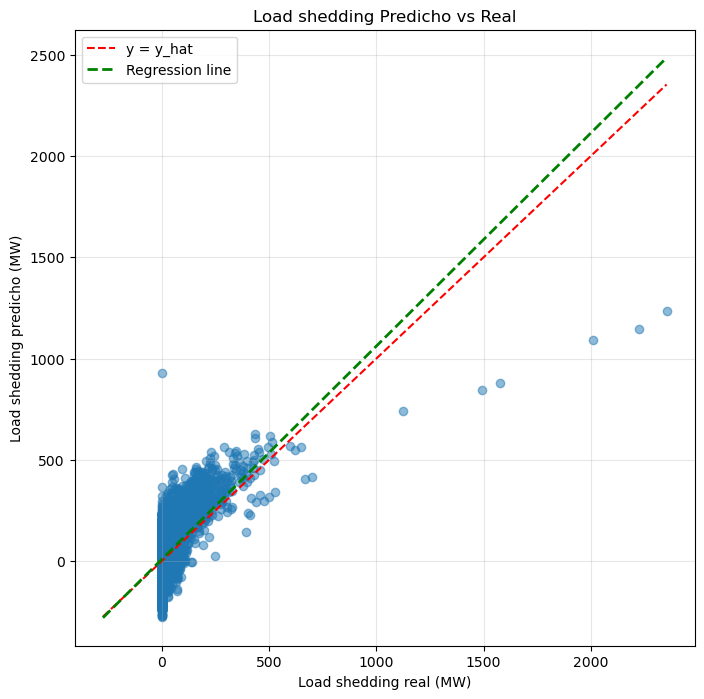

In [67]:
plt.figure(figsize=(8, 8))
plt.scatter(test_set_y, y_pred, alpha=0.5)

min_val = min(np.min(test_set_y), np.min(y_pred))
max_val = max(np.max(test_set_y), np.max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="y = y_hat")

m, b = np.polyfit(test_set_y, y_pred, 1)
x_line = np.linspace(min_val, max_val, 200)
y_line = m * x_line + b
plt.plot(x_line, y_line, color="green", linestyle="--", linewidth=2, label="Regression line")

plt.xlabel("Load shedding real (MW)")
plt.ylabel("Load shedding predicho (MW)")
plt.title("Load shedding Predicho vs Real")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# 14. Análisis de residuales
Calcule los residuales:

$$
e_i = y_i - \hat{y}_i
$$

Construya al menos una gráfica que permita analizar su comportamiento:

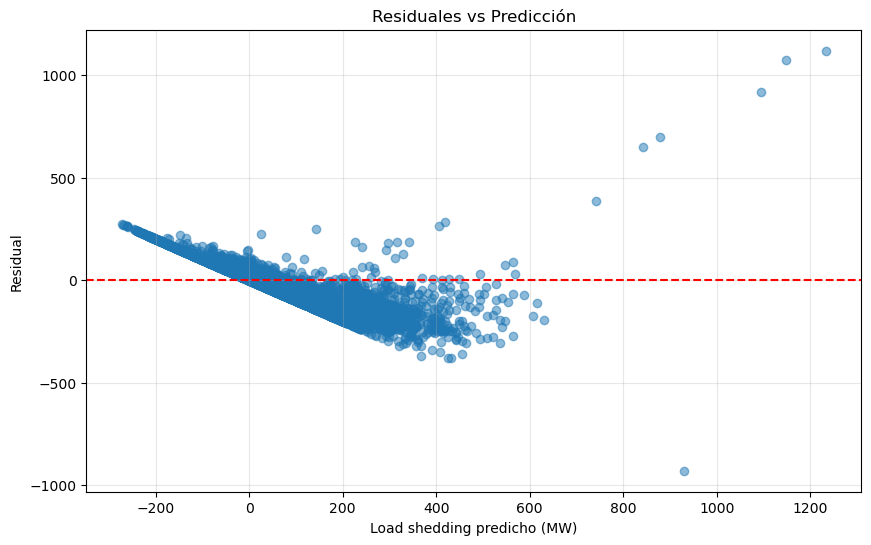

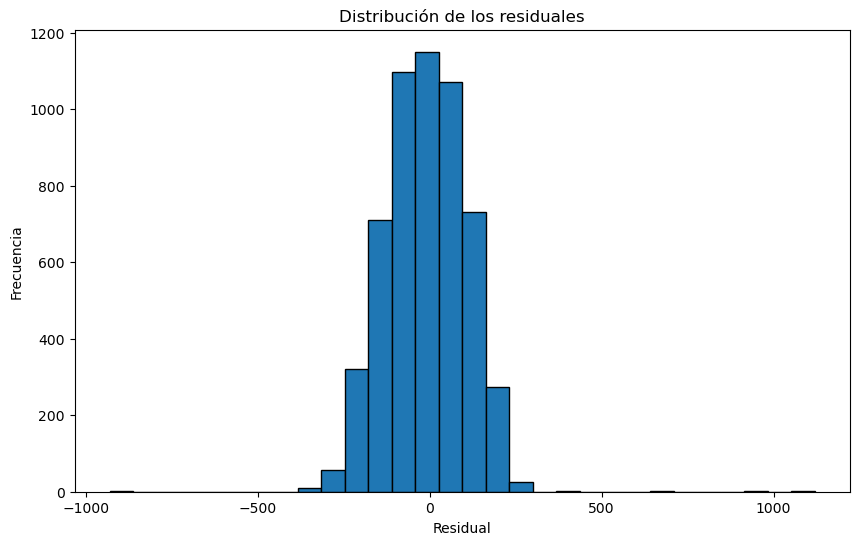

In [68]:
residuals = test_set_y - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuales vs Predicción")
plt.xlabel("Load shedding predicho (MW)")
plt.ylabel("Residual")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, edgecolor='black')
plt.title("Distribución de los residuales")
plt.xlabel("Residual")
plt.ylabel("Frecuencia")
plt.show()

### Preguntas

**¿Los residuales están aproximadamente centrados alrededor de cero?** Si

**¿Existe algún patrón visible en los residuales?**

**¿La dispersión aumenta conforme aumenta la predicción?**

**¿Existen residuales extremos?**

**¿Qué podría indicar la presencia de un patrón sistemático?**

**¿Qué evidencia proporcionan los residuales acerca de si el modelo lineal está capturando adecuadamente la estructura de los datos?**

**¿Qué transformación o característica adicional podría explorar para mejorar el modelo?**

# 15. Load shedding real vs predicho en el tiempo
Compare la evolución del load shedding real con la predicción del modelo final (`best_model`) a lo largo de todo el periodo de estudio:

- **Train:** predicciones del modelo sobre los datos con los que fue entrenado (ajuste).
- **Test:** predicciones sobre datos nunca vistos (generalización).

Se grafican promedios diarios para que la serie sea legible.

### Preguntas

**¿El modelo reproduce la estacionalidad del load shedding en Train?**

**¿Sigue el mismo patrón en Test?**

**¿En qué periodos sobreestima o subestima el load shedding?**

**¿La diferencia entre el ajuste en Train y la predicción en Test indica sobreajuste o un cambio en las condiciones de la red?**

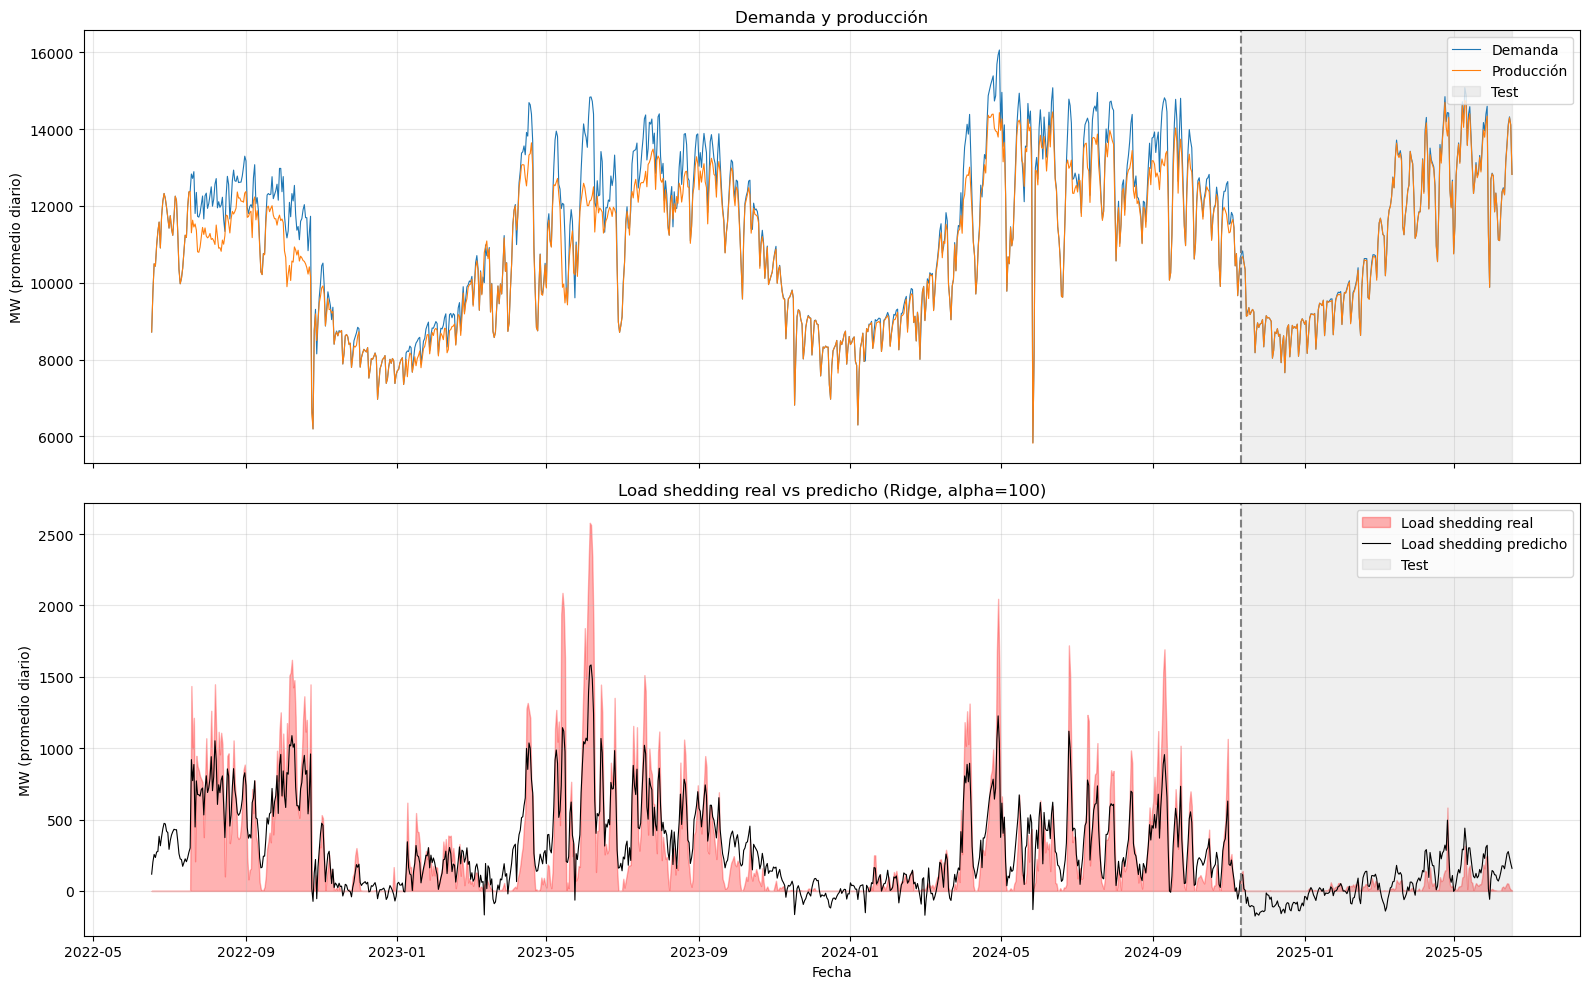

MAE Train (ajuste): 171.29
RMSE Train (ajuste): 299.37
MAE Test (generalización): 92.81
RMSE Test (generalización): 115.59


In [71]:
# Predicciones del modelo final en Train (ajuste) y en Test (generalización)
train_pred = pd.Series(best_model.predict(train_set_x), index=train_set_x.index)
test_pred = pd.Series(y_pred, index=test_set_x.index)

timeline_after = pd.DataFrame({
    "datetime": X["datetime"],
    "demand_mw": X["demand_mw"],
    "generation_mw": X["generation_mw"],
    "load_shedding": X[TARGET],
    "predicted": pd.concat([train_pred, test_pred]),
})
daily_after = timeline_after.groupby(timeline_after["datetime"].dt.date).mean(numeric_only=True)
daily_after.index = pd.to_datetime(daily_after.index)
split_date = test_set_x["datetime"].min()

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

axes[0].plot(daily_after.index, daily_after["demand_mw"], linewidth=0.8, label="Demanda")
axes[0].plot(daily_after.index, daily_after["generation_mw"], linewidth=0.8, label="Producción")
axes[0].set_ylabel("MW (promedio diario)")
axes[0].set_title("Demanda y producción")

axes[1].fill_between(daily_after.index, daily_after["load_shedding"], color="red", alpha=0.3, label="Load shedding real")
axes[1].plot(daily_after.index, daily_after["predicted"], color="black", linewidth=0.8, label="Load shedding predicho")
axes[1].set_ylabel("MW (promedio diario)")
axes[1].set_xlabel("Fecha")
axes[1].set_title(f"Load shedding real vs predicho (Ridge, alpha={best_alpha})")

for ax in axes:
    ax.axvspan(split_date, daily_after.index.max(), color="gray", alpha=0.12, label="Test")
    ax.axvline(split_date, color="gray", linestyle="--")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

train_rmse = np.sqrt(mean_squared_error(train_set_y, train_pred))
test_rmse = np.sqrt(mean_squared_error(test_set_y, test_pred))

print(f"MAE Train (ajuste): {mean_absolute_error(train_set_y, train_pred):.2f}")
print(f"RMSE Train (ajuste): {train_rmse:.2f}")
print(f"MAE Test (generalización): {mean_absolute_error(test_set_y, test_pred):.2f}")
print(f"RMSE Test (generalización): {test_rmse:.2f}")

# 16. Conclusiones